<div dir="rtl" style="text-align: right; line-height: 1.9;">
<h1>تحلیل نظرات کاربران و امتیاز محصولات</h1>
<p>تو این نوت‌بوک داده نظرات کاربرا رو بررسی می‌کنم. هدف اینه که ببینم الگوی امتیازدهی چطوریه کلمات پرتکرار تو نظرای مثبت خنثی و منفی چین کدوم نظردهنده‌ها بیشترین رأی رو گرفتن و کدوم محصولات و برندها برجسته‌ترن.</p>
<p>اول کیفیت و ساختار داده رو چک می‌کنم بعد توزیع امتیازها و متن نظرات رو نگاه می‌کنم و در آخر داده نظرات رو با مشخصات محصولات ترکیب می‌کنم تا نتیجه در سطح محصول و برند هم به دست بیاد.</p>
<p>یه نکته هم بگم نتایجی که اینجا میاد فقط الگوهای موجود تو داده رو نشون میده و به تنهایی رابطه علت و معلولی یا کیفیت قطعی یه محصول رو ثابت نمی‌کنه.</p>
</div>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
train = pd.read_csv("train_data.csv", low_memory=False)
test = pd.read_csv("test_data.csv", low_memory=False)
title = pd.read_csv("title_brand.csv", low_memory=False)

print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")
print(f"Product metadata shape: {title.shape}")

Train shape: (838944, 11)
Test shape: (20000, 10)
Product metadata shape: (786445, 3)


<div dir="rtl" style="text-align: right; line-height: 1.9;">
<h2>۱. بررسی اولیه امتیازها</h2>
<p>ستون overall امتیاز ثبت‌شده هر نظر رو نشون میده. با describe می‌تونم تعداد مقادیر معتبر میانگین پراکندگی و دامنه امتیازها رو تو یه نگاه ببینم.</p>
<p>این مرحله فقط برای شناخت اولیه داده‌ست و بررسی اینکه دامنه امتیازها منطقیه یا نه. ولی به تنهایی نشون نمیده هر امتیاز چندبار ثبت شده برای اون باید بریم سراغ جدول و نمودار که تو بخش بعد میارم.</p>
</div>

In [3]:
train["overall"].describe()

count    838944.000000
mean          4.021317
std           1.344223
min           1.000000
25%           3.000000
50%           5.000000
75%           5.000000
max           5.000000
Name: overall, dtype: float64

In [4]:
datasets = {
    "train": train,
    "test": test,
    "title_brand": title
}

for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(f"Dataset: {name}")
    print(f"{'=' * 50}")
    print("Shape:", df.shape)
    print("Number of rows:", df.shape[0])
    print("Number of columns:", df.shape[1])
    print("\nColumn names:")
    print(df.columns.tolist())
    print("\nData types:")
    print(df.dtypes)


Dataset: train
Shape: (838944, 11)
Number of rows: 838944
Number of columns: 11

Column names:
['overall', 'vote', 'verified', 'reviewTime', 'reviewerID', 'asin', 'style', 'reviewerName', 'reviewText', 'summary', 'unixReviewTime']

Data types:
overall            int64
vote              object
verified            bool
reviewTime        object
reviewerID        object
asin              object
style             object
reviewerName      object
reviewText        object
summary           object
unixReviewTime     int64
dtype: object

Dataset: test
Shape: (20000, 10)
Number of rows: 20000
Number of columns: 10

Column names:
['vote', 'verified', 'reviewTime', 'reviewerID', 'asin', 'style', 'reviewerName', 'reviewText', 'summary', 'unixReviewTime']

Data types:
vote              float64
verified             bool
reviewTime         object
reviewerID         object
asin               object
style              object
reviewerName       object
reviewText         object
summary            object
u

<div dir="rtl" style="text-align: right; line-height: 1.9;">
<h3>تفسیر: شناخت کلی سه فایل داده</h3>
<p>مجموعه داده سه فایل داره. train حدود ۸۳۹ هزار نظر و ۱۱ ستون داره test حدود ۲۰ هزار نظر و title_brand حدود ۷۸۶ هزار ردیف مشخصات محصول شامل asin و title و brand.</p>
<p>ستون overall و vote تو نگاه اول عددی به نظر میان ولی vote از نوع متنیه. این یعنی احتمالاً یه چیزی غیر از عدد خالص توشه مثلاً جداکننده هزارگان و باید قبل از هر محاسبه‌ای پاک‌سازی بشه. همین موضوع رو تو بخش بعد بررسی می‌کنم.</p>
</div>

In [5]:
def missing_report(df):
    report = pd.DataFrame({
        "Missing Count": df.isna().sum(),
        "Missing Percentage": df.isna().mean().mul(100)
    })

    report["Non-Missing Count"] = df.notna().sum()

    return (
        report.sort_values("Missing Percentage", ascending=False)
        .round(2)
    )

for name, df in datasets.items():
    print(f"\nMissing values: {name}")
    display(missing_report(df))


Missing values: train


,Missing Count,Missing Percentage,Non-Missing Count
vote,647476,77.18,191468
style,348331,41.52,490613
reviewerName,227,0.03,838717
summary,76,0.01,838868
overall,0,0.00,838944
verified,0,0.00,838944
reviewTime,0,0.00,838944
asin,0,0.00,838944
reviewerID,0,0.00,838944
reviewText,0,0.00,838944



Missing values: test


,Missing Count,Missing Percentage,Non-Missing Count
vote,15067,75.33,4933
style,8496,42.48,11504
reviewerName,4,0.02,19996
summary,2,0.01,19998
verified,0,0.00,20000
reviewTime,0,0.00,20000
asin,0,0.00,20000
reviewerID,0,0.00,20000
reviewText,0,0.00,20000
unixReviewTime,0,0.00,20000



Missing values: title_brand


,Missing Count,Missing Percentage,Non-Missing Count
brand,5498,0.7,780947
title,19,0.0,786426
asin,0,0.0,786445


In [6]:
for name, df in datasets.items():
    print(f"\n{name}")
    print("Exact duplicate rows:", df.duplicated().sum())

    if "asin" in df.columns:
        print("Rows with duplicated asin:",
            df["asin"].duplicated(keep=False).sum())

        print("Unique non-missing asin:",
            df["asin"].nunique())


train
Exact duplicate rows: 8327
Rows with duplicated asin: 813295
Unique non-missing asin: 90715

test
Exact duplicate rows: 3
Rows with duplicated asin: 10516
Unique non-missing asin: 12750

title_brand
Exact duplicate rows: 30368
Rows with duplicated asin: 60736
Unique non-missing asin: 756077


In [7]:
duplicate_reviews = train.loc[train.duplicated(keep=False)]

display(duplicate_reviews.head(10))

,overall,vote,verified,reviewTime,reviewerID,asin,style,reviewerName,reviewText,summary,unixReviewTime
30174,4,NaN,True,2016-12-01,A11LTGLPJ66GTN,B000VJXS9A,{'Color:': ' Silver'},day tripper,"Incredible sound, but you may experience some ...",Great value fron Koss,1480550400
30175,4,NaN,True,2016-09-17,A31GTTFOJNWJEZ,B000VJXS9A,{'Color:': ' Silver'},Retired Techie,The sound quality of the Koss UR29 headphones ...,Excellent Sound Quality but a little heavier t...,1474070400
30176,5,NaN,True,2016-02-26,A33MI04TY8ZUUF,B000VJXS9A,{'Color:': ' Silver'},Wheelgunner,"This set is comfortable, had good enough range...","This set is comfortable, had good enough range...",1456444800
30177,5,NaN,True,2018-03-09,A3DKMTKGUWKFZK,B000VK5BMQ,{'Package Type:': ' Standard Packaging'},Cleese Amazon Customer,This is a great gadget to add to your bike if ...,Great addition for health nuts!,1520553600
30178,5,NaN,True,2018-01-24,A3C91ZVF3PHZFO,B000VK5BMQ,{'Package Type:': ' Standard Packaging'},Erich,I bought this to be able to mount my Fenix3 on...,I didn't like having my Fenix on my wrist when...,1516752000
30179,5,NaN,True,2017-02-08,AB9DJFD8HTU45,B000VJX7DW,{'Package Type:': ' Standard Packaging'},Robert W. Major,"Am a fussy person, and this deal is almost unb...",Oh great camera!!!,1486512000
30180,5,5.0,True,2017-01-09,A1E2D0JQOAMIFG,B000VJX7DW,{'Package Type:': ' Standard Packaging'},Mr. A,I was looking for a used camera that was fully...,Has everything I need!,1483920000
30181,5,NaN,True,2016-11-29,A1RE4Z7SJ02FPN,B000VJX7DW,{'Package Type:': ' Standard Packaging'},Scott W.,"I'm a professional photographer, and I use thi...",One of my favorites over the years.,1480377600
30182,4,NaN,True,2017-11-05,AKTDFNQ1Q008E,B000VK5BMQ,{'Package Type:': ' Standard Packaging'},BabyGiant,Works ok but 1) there's no easy way to make th...,No rubber spacers,1509840000
30183,5,NaN,True,2017-09-18,A1HWKKMNPZ9042,B000VK5BMQ,{'Package Type:': ' Standard Packaging'},Amazon Customer,This product works great with my Garmin Fenix ...,This product works great with my Garmin Fenix ...,1505692800


<div dir="rtl" style="text-align: right; line-height: 1.9;">
<h3>تفسیر: ردیف‌های تکراری و asinهای تکراری</h3>
<p>تو داده train هشت هزار و سیصد و بیست‌وهفت ردیف پیدا کردم که کاملاً تکراری بودن یعنی تو همه ستون‌ها دقیقاً یکسان. وقتی نمونه‌شو نگاه کردم دیدم اینا واقعاً داده دوبار ثبت‌شده‌ان همون نظردهنده همون تاریخ همون امتیاز. پس این نظرای متفاوتی نیستن که طبیعی روی یه محصول جمع شده باشن بلکه مشکل کیفیت داده‌ست.</p>
<p>تکرار بودن asin تو train طبیعیه چون هر محصول چندتا نظر داره. اینم با نود هزار و هفتصد و پونزده asin یکتا در مقابل بیش از هشتصد و سی‌وهشت هزار ردیف کل جور درمیاد. چیزی که باید نگرانش باشم تکرار asin تو فایل مشخصات محصوله که هر محصول باید فقط یه رکورد مشخصات داشته باشه. اینو تو ادامه جدا بررسی می‌کنم.</p>
</div>

In [8]:
# بررسی امتیازها
if "overall" in train.columns:
    rating_numeric = pd.to_numeric(
        train["overall"], errors="coerce"
    )

    print("Invalid or missing ratings:",
          rating_numeric.isna().sum())

    print("Ratings outside 1–5:",
          (~rating_numeric.dropna().isin([1, 2, 3, 4, 5])).sum())

    print("\nRating distribution:")
    display(rating_numeric.value_counts(dropna=False).sort_index())

# بررسی vote
if "vote" in train.columns:
    vote_numeric = pd.to_numeric(train["vote"], errors="coerce")

    print("\nVote values that cannot be converted:",
          (train["vote"].notna() & vote_numeric.isna()).sum())

    print("Negative vote values:",
          (vote_numeric < 0).sum())

    print("Missing vote values:",
          train["vote"].isna().sum())

Invalid or missing ratings: 0
Ratings outside 1–5: 0

Rating distribution:


overall
1     82950
2     56756
3     81239
4    156514
5    461485
Name: count, dtype: int64


Vote values that cannot be converted: 17
Negative vote values: 0
Missing vote values: 647476


<div dir="rtl" style="text-align: right; line-height: 1.9;">
<h3>تفسیر: اعتبار امتیازها و رأی‌ها</h3>
<p>ستون overall هیچ مقدار گمشده یا خارج از بازه یک تا پنج نداره. یعنی از نظر دامنه کاملاً سالمه و نیازی به پاک‌سازی نداره.</p>
<p>تو ستون vote هفده مقدار بود که مستقیم به عدد تبدیل نمیشد دلیلشو تو ادامه بررسی و رفع می‌کنم و هیچ مقدار منفی هم تو این ستون نبود. حدود ششصد و چهل‌وهفت هزار ردیف هم اصلاً مقدار vote ندارن که با گزارش مقادیر گمشده بخش بعد هم جور درمیاد.</p>
</div>

In [9]:
required_columns = {"asin", "brand", "title"}
missing_columns = required_columns - set(title.columns)

if missing_columns:
    print("Missing expected columns:", missing_columns)
else:
    print("All expected product columns exist.")

    print("Missing asin:",
          title["asin"].isna().sum())

    print("Unique product asin:",
          title["asin"].nunique())

    print("Rows with repeated asin:",
          title["asin"].duplicated(keep=False).sum())

    duplicate_asin_rows = title[
        title["asin"].duplicated(keep=False)
    ].sort_values("asin")

    display(duplicate_asin_rows.head(20))

All expected product columns exist.
Missing asin: 0
Unique product asin: 756077
Rows with repeated asin: 60736


,asin,title,brand
2358,B00000I8D9,Donizetti: Don Pasquale,Philips
32726,B00000I8D9,Donizetti: Don Pasquale,Philips
32729,B00000I9HE,Maxell 203020 HGX-GOLD TC-30 Camcorder Video C...,Maxell
2361,B00000I9HE,Maxell 203020 HGX-GOLD TC-30 Camcorder Video C...,Maxell
2360,B00000I9HF,"Maxell P6-120 GX-MP Camcorder Tapes, 2 Pack",Maxell
32728,B00000I9HF,"Maxell P6-120 GX-MP Camcorder Tapes, 2 Pack",Maxell
32727,B00000I9HG,1-pack CDR Media 74min- for Audio only,Maxell
2359,B00000I9HG,1-pack CDR Media 74min- for Audio only,Maxell
32730,B00000IT8I,Mattel Barbie Clock Radio with Lighted Clock F...,Mattel
2362,B00000IT8I,Mattel Barbie Clock Radio with Lighted Clock F...,Mattel


In [10]:
# کلیدهای غیرخالی و یکتا برای مقایسه
train_asins = set(train["asin"].dropna().unique())
product_asins = set(title["asin"].dropna().unique())

matched_asins = train_asins & product_asins
unmatched_asins = train_asins - product_asins

print("Unique products in train:", len(train_asins))
print("Unique products in metadata:", len(product_asins))
print("Matched product IDs:", len(matched_asins))
print("Train product IDs without metadata:", len(unmatched_asins))

if len(train_asins) > 0:
    match_percentage = len(matched_asins) / len(train_asins) * 100
    print(f"Train product ID match rate: {match_percentage:.2f}%")

Unique products in train: 90715
Unique products in metadata: 756077
Matched product IDs: 90688
Train product IDs without metadata: 27
Train product ID match rate: 99.97%


In [11]:
# تعداد ردیف‌ها و شناسه‌های محصول تکراری
print("Total metadata rows:", len(title))
print("Unique ASINs:", title["asin"].nunique())
print("Rows with duplicated ASIN:", title["asin"].duplicated(keep=False).sum())

# نمایش چند نمونه از ASINهای تکراری
duplicate_asins = title.loc[
    title["asin"].duplicated(keep=False)
].sort_values("asin")

display(duplicate_asins.head(20))

Total metadata rows: 786445
Unique ASINs: 756077
Rows with duplicated ASIN: 60736


,asin,title,brand
2358,B00000I8D9,Donizetti: Don Pasquale,Philips
32726,B00000I8D9,Donizetti: Don Pasquale,Philips
32729,B00000I9HE,Maxell 203020 HGX-GOLD TC-30 Camcorder Video C...,Maxell
2361,B00000I9HE,Maxell 203020 HGX-GOLD TC-30 Camcorder Video C...,Maxell
2360,B00000I9HF,"Maxell P6-120 GX-MP Camcorder Tapes, 2 Pack",Maxell
32728,B00000I9HF,"Maxell P6-120 GX-MP Camcorder Tapes, 2 Pack",Maxell
32727,B00000I9HG,1-pack CDR Media 74min- for Audio only,Maxell
2359,B00000I9HG,1-pack CDR Media 74min- for Audio only,Maxell
32730,B00000IT8I,Mattel Barbie Clock Radio with Lighted Clock F...,Mattel
2362,B00000IT8I,Mattel Barbie Clock Radio with Lighted Clock F...,Mattel


In [12]:
# تعداد ردیف‌های متفاوت برای هر ASIN
duplicate_details = (
    title[title["asin"].duplicated(keep=False)]
    .groupby("asin", dropna=False)
    .agg(
        row_count=("asin", "size"),
        unique_brands=("brand", "nunique"),
        unique_titles=("title", "nunique")
    )
    .sort_values("row_count", ascending=False)
)

display(duplicate_details.head(20))

,row_count,unique_brands,unique_titles
asin,,,
B0004HQQW0,2,1,1
B0004HQQSE,2,1,1
B0004HQQ1G,2,1,1
B0004HQEQI,2,1,1
B0004HQ19I,2,1,1
B0004HPY28,2,1,1
B0004HPV58,2,1,1
B0004HPEIM,2,1,1
B0004FQRLC,2,1,1


<div dir="rtl" style="text-align: right; line-height: 1.9;">
<h3>تفسیر: بررسی فایل مشخصات محصول</h3>
<p>فایل مشخصات محصول هر سه ستون لازمو داره asin و brand و title و هیچ asin خالی هم نداره. از نود هزار و هفتصد و پونزده محصول یکتا که تو داده نظرات هست نود هزار و ششصد و هشتادوهشت تاش یعنی نود و نه و نیم درصد تو فایل مشخصات محصول هم هست. پس تقریباً برای همه محصولا میشه برند و عنوانو پیدا کرد.</p>
<p>وقتی تکرارای asin رو دقیق‌تر نگاه کردم دیدم بیشتر وقتا یه محصول فقط دوبار تکرار شده و تعداد برند و عنوان یکتا برای اون asin تکراری همون یه مقداره. یعنی از همون اول معلوم بود این تکرارا احتمالاً کپی کاملن نه ناسازگاری واقعی تو داده. اینو تو مرحله بعد که تکرارای دقیق رو حذف کردم تأیید کردم.</p>
</div>

In [13]:
title_clean = title.drop_duplicates().copy()

# بررسی اینکه هنوز ASIN تکراری وجود دارد یا نه
print("Remaining duplicate ASINs:",
      title_clean["asin"].duplicated().sum())

Remaining duplicate ASINs: 0


In [14]:
# 1. حذف ردیف‌هایی که در تمام ستون‌ها دقیقاً یکسان‌اند
title_clean = title.drop_duplicates().copy()

# 2. پیدا کردن ASINهایی که هنوز بیش از یک ردیف دارند
remaining_duplicates = title_clean[
    title_clean.duplicated(subset="asin", keep=False)
].sort_values("asin")

print("Rows before cleaning:", len(title))
print("Rows after exact deduplication:", len(title_clean))
print("ASINs with conflicting metadata:",
      remaining_duplicates["asin"].nunique())

# 3. نمایش نمونه‌های دارای اطلاعات متناقض
display(remaining_duplicates.head(30))

Rows before cleaning: 786445
Rows after exact deduplication: 756077
ASINs with conflicting metadata: 0


,asin,title,brand


In [15]:
conflict_summary = (
    title_clean.groupby("asin")
    .agg(
        row_count=("asin", "size"),
        unique_titles=("title", "nunique"),
        unique_brands=("brand", "nunique")
    )
    .query("row_count > 1")
    .sort_values(
        ["unique_brands", "unique_titles", "row_count"],
        ascending=False
    )
)

print("ASINs with multiple metadata rows:", len(conflict_summary))
print("ASINs with multiple brands:",
      (conflict_summary["unique_brands"] > 1).sum())
print("ASINs with multiple titles:",
      (conflict_summary["unique_titles"] > 1).sum())

display(conflict_summary.head(20))

ASINs with multiple metadata rows: 0
ASINs with multiple brands: 0
ASINs with multiple titles: 0


,row_count,unique_titles,unique_brands
asin,,,


In [16]:
# ادغام داده‌ها و بررسی صحت آن
merged_check = train.merge(
    title_clean,
    on="asin",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Rows before merge:", len(train))
print("Rows after merge:", len(merged_check))

print("\nMetadata match status:")
print(merged_check["_merge"].value_counts())

matched = (merged_check["_merge"] == "both").sum()
unmatched = (merged_check["_merge"] == "left_only").sum()
match_rate = matched / len(train) * 100

print(f"\nMatched reviews: {matched:,}")
print(f"Reviews without metadata: {unmatched:,}")
print(f"Metadata match rate: {match_rate:.2f}%")

# اطمینان از اینکه ادغام تعداد نظرات را تغییر نداده است
assert len(merged_check) == len(train), \
    "Error: merge changed the number of rows!"

print("\nMerge validation passed successfully.")

Rows before merge: 838944
Rows after merge: 838944

Metadata match status:
_merge
both          838867
left_only         77
right_only         0
Name: count, dtype: int64

Matched reviews: 838,867
Reviews without metadata: 77
Metadata match rate: 99.99%

Merge validation passed successfully.


In [17]:
unmatched_reviews = merged_check.loc[
    merged_check["_merge"] == "left_only",
    ["asin", "overall", "reviewText"]
]

print("Unmatched review rows:", len(unmatched_reviews))
print("Unique unmatched ASINs:", unmatched_reviews["asin"].nunique())

display(unmatched_reviews.head(10))

Unmatched review rows: 77
Unique unmatched ASINs: 27


,asin,overall,reviewText
35473,B00140TJF2,5,I had purchased one of the cheap batteries at ...
35474,B00140TJF2,5,Great battery!!! I almost bought a much cheap...
35475,B00141B82I,3,The color is vibrant and pleasant. I like the ...
35476,B00141B82I,5,I had to replace these exact mouse-pads initia...
36927,B0016231VQ,5,so this is a really nice case. it has a nice r...
37633,B0016ZMMW2,5,"I have kids. They lose things, like laptop po..."
37634,B0016ZMMW2,5,The PWR+ charger was really good. I had two ot...
37635,B0016ZMMW2,5,Every year or so I need to buy a new AC adapte...
37636,B0016ZMMW2,5,I was impressed with the quality of the charge...
37840,B00175GFGK,5,Price is a tad bit steep but pelican is a grea...


<div dir="rtl" style="text-align: right; line-height: 1.9;">
<h3>تفسیر: کیفیت ادغام نظرات با مشخصات محصول</h3>
<p>قبل از ادغام چک کردم که فایل مشخصات محصول برای هر asin فقط یه ردیف داره یا نه. دیدم شصت هزار و هفتصد و سی‌وشش ردیف asin تکراری دارن. ولی وقتی فقط تکرارای کاملاً یکسانو حذف کردم همه این تکرارا از بین رفتن و دیگه هیچ asinی با اطلاعات متناقض نمونده. یعنی تکرارا فقط رکورد کپی‌شده بودن نه دوتا محصول متفاوت با یه کد.</p>
<p>این یعنی نسخه پاک‌سازی‌شده title_clean برای ادغام با نظرات امنه چون هر asin دقیقاً یه برند و یه عنوان داره و میشه با خیال راحت merge زد بدون نگرانی از زیاد شدن تعداد ردیفا.</p>
<p>بعد از ادغام هشتصد و سی‌وهشت هزار و هشتصدوشصت‌وهفت نظر از کل هشتصد و سی‌وهشت هزار و نهصد و چهل‌وچهار نظر یعنی نود و نه و نود و نه صدم درصد به مشخصات محصول وصل شدن و فقط هفتادوهفت نظر مربوط به بیست‌وهفت محصول بدون رکورد مشخصات موند. اینا سهم خیلی کمی از کل داده‌ان و میانگین امتیازشونم با بقیه داده فرق چندانی نداره پس نگه داشتن یا کنار گذاشتنشون تأثیر زیادی رو نتیجه نهایی نمیذاره.</p>
</div>

In [18]:
vote_numeric = pd.to_numeric(train["vote"], errors="coerce")

invalid_vote_values = train.loc[
    train["vote"].notna() & vote_numeric.isna(),
    ["vote"]
]

print("Invalid non-missing vote values:", len(invalid_vote_values))
display(invalid_vote_values["vote"].value_counts())

Invalid non-missing vote values: 17


vote
1,489    2
1,197    1
1,020    1
1,193    1
1,116    1
1,820    1
1,044    1
1,289    1
1,875    1
2,846    1
2,433    1
1,372    1
1,560    1
1,149    1
1,524    1
1,542    1
Name: count, dtype: int64

In [19]:
unmatched_summary = (
    unmatched_reviews.groupby("asin")
    .agg(
        review_count=("overall", "size"),
        average_rating=("overall", "mean")
    )
    .sort_values("review_count", ascending=False)
    .reset_index()
)

display(unmatched_summary)

,asin,review_count,average_rating
0,B00192KF12,19,4.736842
1,B0016ZMMW2,8,5.000000
2,B00175GFGK,6,4.666667
3,B00140TJF2,5,5.000000
4,B00141B82I,4,4.000000
5,B00156N5OG,3,3.333333
6,B0016231VQ,2,5.000000
7,B0016BUKJS,2,3.500000
8,B0013MV792,2,4.500000
9,B0013HRKB6,2,3.500000


In [20]:
# نمایش مقادیر اصلی و تبدیل آزمایشی
invalid_votes = train.loc[
    train["vote"].notna()
    & pd.to_numeric(train["vote"], errors="coerce").isna(),
    "vote"
]

vote_cleaned = (
    invalid_votes.astype(str)
    .str.replace(",", "", regex=False)
)

vote_test = pd.to_numeric(vote_cleaned, errors="coerce")

display(
    pd.DataFrame({
        "Original vote": invalid_votes,
        "After removing commas": vote_cleaned,
        "Converted value": vote_test
    })
)

print("Still unconvertible after cleanup:", vote_test.isna().sum())

,Original vote,After removing commas,Converted value
449157,"1,489",1489,1489
456142,"1,489",1489,1489
477654,"1,197",1197,1197
483105,"1,020",1020,1020
554050,"1,193",1193,1193
561354,"1,116",1116,1116
607633,"1,820",1820,1820
628820,"1,044",1044,1044
651645,"1,289",1289,1289
653614,"1,875",1875,1875


Still unconvertible after cleanup: 0


In [21]:
# پاک‌سازی vote، حذف جداکننده هزارگان و تبدیل به عدد
for df in [train, test]:
    df["vote"] = pd.to_numeric(
        df["vote"]
        .astype("string")
        .str.replace(",", "", regex=False),
        errors="coerce"
    )

print("Train vote dtype:", train["vote"].dtype)
print("Test vote dtype:", test["vote"].dtype)

print("Missing vote values in train:", train["vote"].isna().sum())
print("Non-missing vote values in train:", train["vote"].notna().sum())
print("Negative vote values in train:", (train["vote"].dropna() < 0).sum())

Train vote dtype: Float64
Test vote dtype: Float64
Missing vote values in train: 647476
Non-missing vote values in train: 191468
Negative vote values in train: 0


In [22]:
# مقادیر اصلی vote قبل از تبدیل باید از نسخه اولیه یا فایل اصلی خوانده شوند.
# در حال حاضر، train["vote"] از قبل تبدیل شده است.

print("Missing vote values:", train["vote"].isna().sum())
print("Non-missing vote values:", train["vote"].notna().sum())
print("Negative vote values:", (train["vote"].dropna() < 0).sum())

display(train["vote"].describe())

Missing vote values: 647476
Non-missing vote values: 191468
Negative vote values: 0


count     191468.0
mean      7.546217
std      26.985998
min            2.0
25%            2.0
50%            3.0
75%            6.0
max         2846.0
Name: vote, dtype: Float64

<div dir="rtl" style="text-align: right; line-height: 1.9;">
<h3>تفسیر: پاک‌سازی ستون vote</h3>
<p>وقتی vote رو به عدد تبدیل کردم هفده مقدار قابل تبدیل نبود. وقتی خود مقادیرو نگاه کردم مثل ۱۴۸۹ و ۲۸۴۶ دیدم دلیلش جداکننده هزارگانه یعنی کاما نه اینکه داده واقعاً خراب باشه. برای همین قبل از تبدیل کاما رو حذف کردم و بعد از این کار هر هفده مقدار بدون مشکل تبدیل شد و هیچ مقدار منفی هم تو کل ستون نبود.</p>
<p>بعد از تبدیل نهایی حدود ششصد و چهل‌وهفت هزار ردیف یعنی هفتادوهفت درصد مقدار vote ندارن و حدود صدونودویک هزار ردیف مقدار معتبر دارن. میانگین رأیا تو نظرایی که رأی دارن حدود هفت و نیمه میانه سه و حداکثرش به ۲۸۴۶ میرسه. یعنی توزیع رأیا هم مثل طول متن خیلی کشیده به سمت راسته اکثر نظرا رأی کم دارن و تعداد کمی رأی خیلی زیاد گرفتن.</p>
<p>یه نکته مهم هم هست خالی بودن vote احتمالاً یعنی اون نظر اصلاً رأی نگرفته نه اینکه داده‌ش گم شده باشه. برای همین تو تحلیل ده نظردهنده با بیشترین رأی مقادیر خالی رو صفر در نظر گرفتم. این یه فرض تحلیلیه و باید تو گزارش بهش اشاره کرد.</p>
</div>

<div dir="rtl" style="text-align: right; line-height: 1.9;">
<h2>۲. بررسی مقادیر گمشده</h2>
<p>اینجا تعداد و درصد مقادیر خالی هر ستونو حساب می‌کنم. این کارو قبل از تحلیل انجام میدم چون ممکنه بعضی متغیرا برای همه ردیفا در دسترس نباشن و این رو تحلیلای بعدی اثر بذاره.</p>
<p>تو خروجی ستون vote حدود هفتادوهفت درصد و ستون style حدود چهل‌ویک درصد مقدار گمشده دارن. در مقابل تعداد مقادیر گمشده تو reviewerName و summary خیلی کمه.</p>
<p>تو این مرحله هیچ ردیفی حذف نمی‌کنم و جایگزینم نمی‌کنم فقط وضعیت داده رو ثبت می‌کنم. اینکه با مقادیر گمشده چیکار کنم بستگی به هدف هر تحلیل داره. مثلاً تو تحلیل مجموع رأیا مقدار خالی vote تو کد صفر در نظر گرفته میشه که یه فرض عملیاتیه نه اثبات اینکه اون نظر واقعاً هیچ رأیی نداشته.</p>
</div>

In [23]:
nan_info = pd.DataFrame({
    "NaN Count": train.isna().sum(),
    "NaN Percentage": train.isna().mean() * 100
})

print(nan_info[nan_info["NaN Count"] > 0].sort_values(
    "NaN Percentage", ascending=False
))
#برسی NaN

              NaN Count  NaN Percentage
vote             647476       77.177499
style            348331       41.520173
reviewerName        227        0.027058
summary              76        0.009059


<div dir="rtl" style="text-align: right; line-height: 1.9;">
<h2>۳. توزیع امتیازهای کاربران</h2>
<p>اول یه نمودار از تعداد نظرات برای امتیازای یک تا پنج می‌کشم بعد جدول فراوانی و درصد هر امتیازو می‌سازم. وقتی تعداد و درصد رو با هم نشون بدم مقایسه کلاسا راحت‌تر میشه مخصوصاً وقتی تعداد کل نظرات زیاده.</p>
<p>تو نمودار محور افقی امتیاز ستاره‌ای و محور عمودی تعداد نظراته. بالای هر میله هم تعداد دقیق نظرات همون امتیاز نوشته شده.</p>
</div>

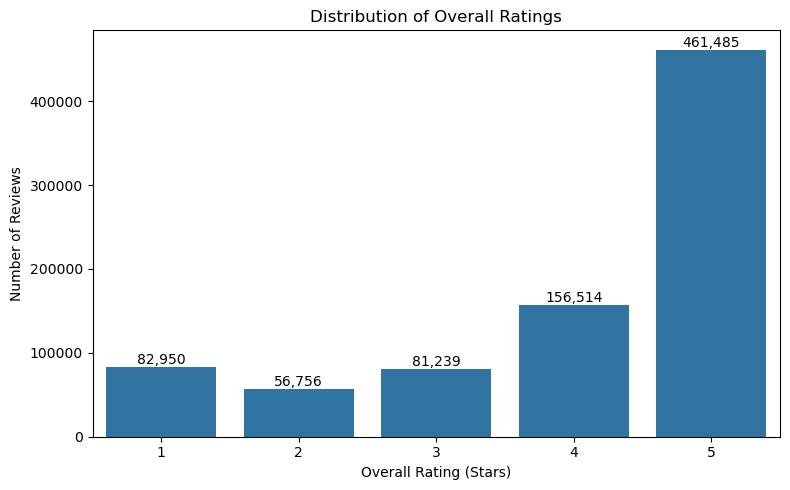

In [24]:
# رسم نمودار توزیع با اندازه مشخص
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=train,
    x="overall",
    order=[1, 2, 3, 4, 5]
)

plt.title("Distribution of Overall Ratings")
plt.xlabel("Overall Rating (Stars)")
plt.ylabel("Number of Reviews")

# نمایش تعداد هر کلاس بالای میله
for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height()):,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [25]:
# ساخت جدول فراوانی و درصد هر امتیاز
rating_summary = (
    train["overall"]
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
    .rename_axis("Rating")
    .reset_index(name="Count")
)

rating_summary["Percentage"] = (
    rating_summary["Count"] / len(train) * 100
).round(2)

display(rating_summary)

,Rating,Count,Percentage
0,1,82950,9.89
1,2,56756,6.77
2,3,81239,9.68
3,4,156514,18.66
4,5,461485,55.01


<div dir="rtl" style="text-align: right; line-height: 1.9;">
<h3>تفسیر توزیع امتیازها</h3>
<p>طبق جدول فراوانی امتیاز پنج با چهارصد و شصت‌ویک هزار و چهارصد و هشتادوپنج نظر و سهم پنجاه‌وپنج درصدی پرتکرارترین امتیازه. بعدش امتیاز چهار با صدوپنجاه‌وشش هزار و پونصد و چهارده نظر و سهم هجده و شصت‌وشش درصد قرار داره. کمترین فراوانی مال امتیاز دوئه که پنجاه‌وشش هزار و هفتصد و پنجاه‌وشش نظر یعنی شش و هفتادوهفت درصد از کل نظراته.</p>
<p>امتیازای چهار و پنج روی هم هفتادوسه و شصت‌وشش درصد از نظراتو میسازن. در مقابل امتیازای یک و دو روی هم شونزده و شصت‌وپنج درصدن و امتیاز سه هم نه و شصت‌وهشت درصد از کل نظراته. یعنی کاربرا تو این داده بیشتر امتیاز بالا دادن.</p>
<p>پس توزیع امتیازا نامتوازنه. اگه بعداً از این امتیازا برای ساخت مدل طبقه‌بندی استفاده بشه ممکنه مدل تو پیش‌بینی کلاسای پرتکرار بهتر عمل کنه. برای همین بهتره علاوه بر دقت کلی معیارایی مثل Macro F1 و ماتریس درهم‌ریختگی رو هم نگاه کنیم.</p>
<p>فعلاً نیازی به متوازن‌سازی داده نیست. اول باید عملکرد مدل پایه رو ببینم بعد اگه مدل تو تشخیص کلاسای کم‌تعداد ضعیف بود میرم سراغ وزن‌دهی کلاسا یا نمونه‌برداری مجدد. هر نوع نمونه‌برداریم باید فقط روی داده آموزش انجام بشه.</p>
</div>

<div dir="rtl" style="text-align: right; line-height: 1.9;">
<h2>۴. تحلیل متن نظرات با ابر کلمات</h2>
<p>برای مقایسه واژگان رایج تو نظرات امتیازا رو سه گروه کردم مثبت که چهار و پنجه خنثی که سه‌ئه و منفی که یک و دوئه. این دسته‌بندی فقط برای اکتشاف اولیه متنه و جای تحلیل دقیق احساس یا مدل زبانی رو نمی‌گیره.</p>
<p>قبل از ساخت ابر کلمات ردیفای بدون متنو حذف کردم و متنا رو به حروف کوچیک تبدیل کردم. بعد تگ اچ‌تی‌ام‌ال لینکا و کاراکترای غیرحرفی رو حذف کردم. کلمات خیلی رایج انگلیسی و چندتا کلمه عمومی مرتبط با خرید رو هم به لیست استاپ‌وردز اضافه کردم تا فضای بیشتری برای کلمات موضوعی بمونه.</p>
<p>کلماتی مثل the و and معمولاً تو خیلی از جمله‌ها میان و به تنهایی تفاوت محتوایی گروه‌ها رو روشن نمی‌کنن. البته پاک‌سازی متن همیشه یه تصمیم تحلیلیه و حذف بیش از حد کلمات ممکنه اطلاعات مفیدی رو هم از بین ببره.</p>
</div>

In [26]:
import re
from collections import Counter
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

In [27]:
# حذف ردیف‌هایی که متن نظر ندارند
data = train.dropna(subset=["reviewText"]).copy()

# تبدیل متن به رشته
data["reviewText"] = data["reviewText"].astype(str)

# دسته‌بندی نظرات بر اساس امتیاز
positive_reviews = data.loc[data["overall"].isin([4, 5]), "reviewText"]
neutral_reviews = data.loc[data["overall"] == 3, "reviewText"]
negative_reviews = data.loc[data["overall"].isin([1, 2]), "reviewText"]

# کلمات زائد انگلیسی
custom_stopwords = set(STOPWORDS)
custom_stopwords.update({
    "product", "one", "would", "could", "get",
    "also", "really", "much", "even", "still",
    "amazon", "buy", "bought", "purchase",
    "use", "used", "using", "item", "thing"
})

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)  # حذف HTML
    text = re.sub(r"http\S+|www\S+", " ", text)  # حذف لینک‌ها
    text = re.sub(r"[^a-z\s]", " ", text)  # نگه‌داشتن حروف انگلیسی
    words = [
        word for word in text.split()
        if len(word) > 2 and word not in custom_stopwords
    ]
    return " ".join(words)

positive_text = clean_text(" ".join(positive_reviews))
neutral_text = clean_text(" ".join(neutral_reviews))
negative_text = clean_text(" ".join(negative_reviews))

print("Positive reviews:", len(positive_reviews))
print("Neutral reviews:", len(neutral_reviews))
print("Negative reviews:", len(negative_reviews))

Positive reviews: 617999
Neutral reviews: 81239
Negative reviews: 139706


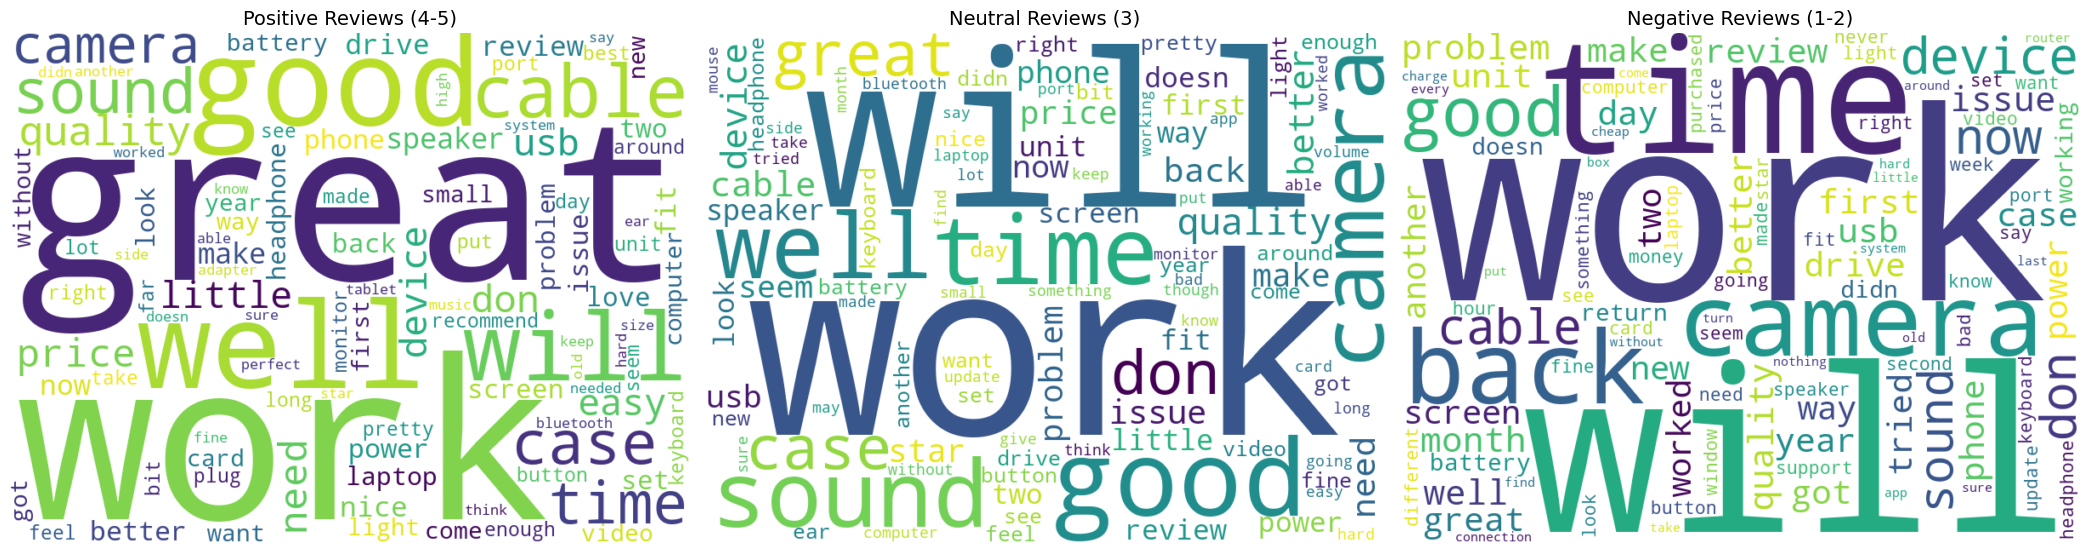

In [28]:
texts = {
    "Positive Reviews (4-5)": positive_text,
    "Neutral Reviews (3)": neutral_text,
    "Negative Reviews (1-2)": negative_text
}

fig, axes = plt.subplots(1, 3, figsize=(21, 7))

for ax, (wc_title, text) in zip(axes, texts.items()):
    if text.strip():
        wc = WordCloud(
            width=800,
            height=600,
            background_color="white",
            stopwords=custom_stopwords,
            max_words=100,
            collocations=False
        ).generate(text)

        ax.imshow(wc, interpolation="bilinear")
        ax.set_title(wc_title, fontsize=14)
        ax.axis("off")
    else:
        ax.set_title(f"{wc_title} - No text")
        ax.axis("off")

plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align: right; line-height: 1.9;">
<h3>تفسیر ابر کلمات</h3>
<p>تعداد نظرات هر گروه تو خروجی کد نشون میده ششصد و هفده هزار و نهصد و نودونه نظر تو گروه مثبت هشتادویک هزار و دویست و سی‌ونه نظر تو گروه خنثی و صدوسی‌ونه هزار و هفتصد و شش نظر تو گروه منفی قرار گرفتن. این تعدادا بر اساس گروه‌بندی امتیازا تعریف شدن پس مثبت بودن اینجا یعنی امتیاز چهار یا پنج نه نتیجه یه مدل مستقل تحلیل احساس.</p>
<p>تو ابر کلمات واژه‌هایی مثل great و good و work و sound و quality تو گروه مثبت برجسته‌ان. تو گروه خنثی واژه‌هایی مثل work و sound و quality و problem دیده میشن و تو گروه منفی هم work و time و back و problem و quality پرتکرارن.</p>
<p>اینکه کلمه‌هایی مثل work و quality تو چندتا گروه مشترکن طبیعیه. کاربرا تو همه گروه‌ها ممکنه درباره عملکرد و کیفیت محصول حرف بزنن ولی نتیجه‌گیریشون فرق کنه. مثلاً works well و does not work هر دو کلمه work رو دارن ولی معنای احساسی کاملاً متفاوتی میدن.</p>
<p>یه محدودیتم هست اندازه کلمه تو ابر کلمات فقط فراوانیشو نشون میده نه مثبت یا منفی بودن معنیشو. همینطور چون تعداد نظرات گروه‌ها برابر نیست مقایسه اندازه کلمات بین گروه‌ها باید با احتیاط انجام بشه. برای تحلیل دقیق‌تر میشه فراوانی نسبی کلمات و عبارتای چندکلمه‌ای و بافت جمله رو هم بررسی کرد.</p>
</div>

<div dir="rtl" style="text-align: right; line-height: 1.9;">
<h2>۵. طول متن نظرات (reviewText)</h2>
<p>اینجا طول هر نظرو بر اساس تعداد کاراکتر ستون reviewText حساب می‌کنم و توزیعشو با هیستوگرام می‌کشم. اول حالت کامل بدون هیچ فیلتری و بعد حالت فیلترشده که دنباله خیلی پرت و کم‌نمونه سمت راستو کنار میذارم تا شکل اصلی توزیع بهتر دیده بشه.</p>
</div>

count    838944.000000
mean        624.687384
std         684.129474
min         200.000000
25%         277.000000
50%         408.000000
75%         697.000000
max       29146.000000
Name: text_length, dtype: float64


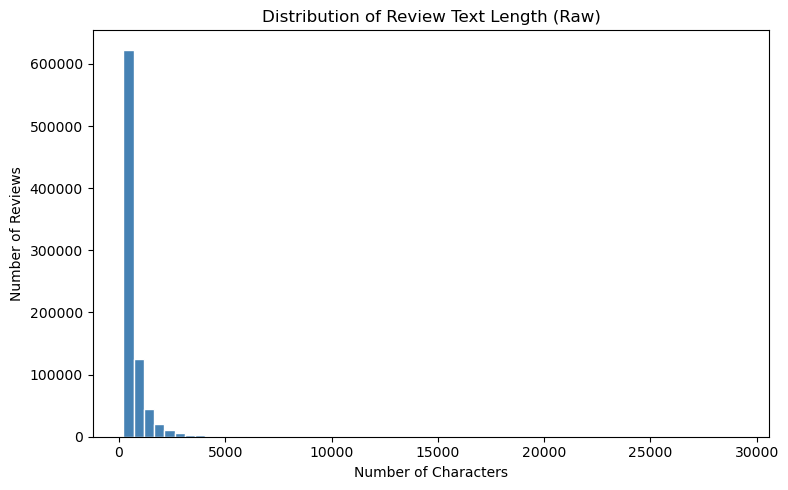

In [29]:
# طول متن هر نظر بر حسب تعداد کاراکتر
review_len = train.dropna(subset=["reviewText"]).copy()
review_len["reviewText"] = review_len["reviewText"].astype(str)
review_len["text_length"] = review_len["reviewText"].str.len()

print(review_len["text_length"].describe())

# هیستوگرام حالت اصلی (بدون فیلتر)
plt.figure(figsize=(8, 5))
plt.hist(review_len["text_length"], bins=60, color="steelblue", edgecolor="white")
plt.title("Distribution of Review Text Length (Raw)")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

0.900    1217.000
0.950    1733.000
0.990    3399.000
0.995    4357.000
0.999    7224.114
Name: text_length, dtype: float64

Upper cutoff (99th percentile): 3399 characters
Rows kept after filtering: 830,555 / 838,944 (99.00%)


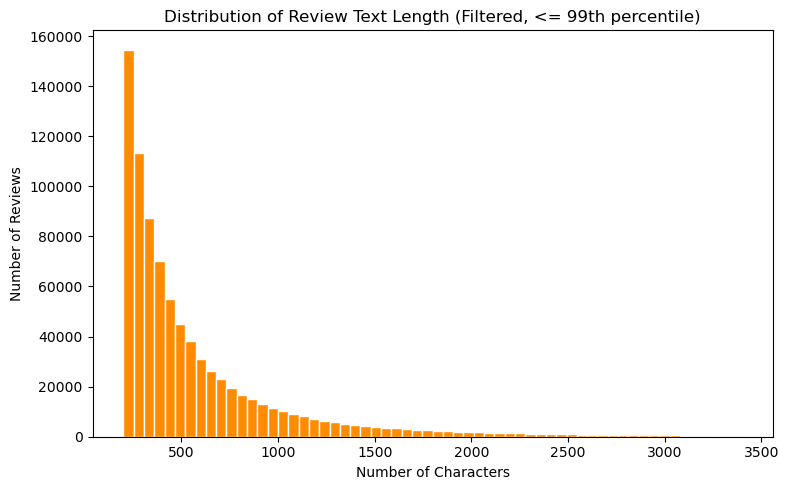

In [30]:
# بررسی صدک‌های بالا برای تشخیص دنباله پرت و کم‌نمونه
print(review_len["text_length"].quantile([0.90, 0.95, 0.99, 0.995, 0.999]))

# فیلتر کردن طول‌های بسیار پرت (صدک ۹۹ به‌عنوان آستانه‌ی بالا) برای رسم خواناتر
upper_cutoff = review_len["text_length"].quantile(0.99)
filtered_len = review_len.loc[review_len["text_length"] <= upper_cutoff, "text_length"]

print(f"\nUpper cutoff (99th percentile): {upper_cutoff:.0f} characters")
print(f"Rows kept after filtering: {len(filtered_len):,} / {len(review_len):,} "
      f"({len(filtered_len) / len(review_len) * 100:.2f}%)")

plt.figure(figsize=(8, 5))
plt.hist(filtered_len, bins=60, color="darkorange", edgecolor="white")
plt.title("Distribution of Review Text Length (Filtered, <= 99th percentile)")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align: right; line-height: 1.9;">
<h3>تفسیر توزیع طول متن</h3>
<p>تو حالت اصلی بدون فیلتر بیشتر نظرات طول کوتاهی دارن و توزیع خیلی کشیده به راسته. یعنی اکثر مقادیر تو بازه کوتاه جمع شدن ولی تعداد کمی نظر خیلی طولانی هم هست که باعث میشه محور افقی کشیده بشه و جزئیات بخش اصلی توزیع خوب دیده نشه.</p>
<p>تو نسخه فیلترشده با کنار گذاشتن طولای بالاتر از صدک نودونه که نماینده همون دنباله کم‌نمونه‌ست شکل اصلی توزیع تو بازه رایج‌تر طول نظرات واضح‌تر دیده میشه.</p>
<p>به نظرم باید هنگام مدل‌سازی رو طول متن محدودیت بذاریم به دو دلیل. اول نظرای خیلی کوتاه مثلاً چندتا کاراکتر یا خالی بعد پاک‌سازی اطلاعات متنی قابل اتکایی برای یادگیری الگوی احساس نمیدن و فقط نویزن. دوم نظرای خیلی بلند هم نمونه‌شون کمه هم وقت پردازش و طول توکن‌سازیو خیلی میبره بالا بدون اینکه سود چندانی داشته باشه و ممکنه شامل محتوای نامرتبط باشن مثلاً چندتا نظر به هم چسبیده.</p>
<p>بر اساس صدکایی که تو کد بالا حساب کردم پیشنهادم اینه که نظرای زیر پنج تا ده کاراکتر که عملاً محتوای معناداری ندارن حذف بشن و نظرای بالاتر از صدک نودونه هم به عنوان دنباله پرت کنار گذاشته یا بریده بشن. عدد دقیقشو باید بعد اجرای واقعی کد روی داده خودتون ببینید و بر اساس اون نهایی کنید.</p>
</div>

<div dir="rtl" style="text-align: right; line-height: 1.9;">
<h2>۶. ده نظر‌دهنده با بیشترین مجموع رأی</h2>
<p>اینجا ستون vote رو عددی می‌کنم تا بتونم رأیای هر نظردهندرو جمع بزنم. مقادیر خالی یا نامعتبر رو صفر در نظر می‌گیرم و ردیفایی که نام نظردهنده ندارن تو گروه‌بندی نمیان. بعد مجموع رأیا رو برای هر اسم حساب می‌کنم و ده تای بزرگتر رو انتخاب می‌کنم.</p>
<p>تو خروجی Amazon Customer با مجموع بیست‌وهشت هزار و هشتصد و هفتادویک رأی اول شده و بعدش اسمایی مثل Benson Leung و Michael میان.</p>
<p>یه نکته مهم اینه که این فقط مجموع رأیاست نه تعداد نظر یا کیفیت قطعی نظرات. اسمای عمومی مثل Amazon Customer یا Michael ممکنه به چند آدم مختلف اشاره کنن پس نباید هر اسمو حتماً یه هویت یکتا فرض کرد. جایگزین کردن رأی خالی با صفرم رو نتیجه مجموعا اثر میذاره و باید تو گزارش بهش اشاره بشه.</p>
</div>

In [31]:
# تبدیل vote به مقدار عددی در یک نسخه موقت٬ داده اصلی train تغییر نمی‌کند
vote_numeric = pd.to_numeric(train["vote"], errors="coerce").fillna(0)

# نام نظر‌دهنده‌های موجود را همراه با رأی‌ها نگه می‌داریم
valid_reviews = train.loc[train["reviewerName"].notna(), ["reviewerName"]].copy()
valid_reviews["vote_numeric"] = vote_numeric.loc[valid_reviews.index]

reviewer_votes = (
    valid_reviews.groupby("reviewerName")["vote_numeric"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

reviewer_votes.columns = ["Reviewer Name", "Total Votes"]
reviewer_votes

,Reviewer Name,Total Votes
0,Amazon Customer,28871.0
1,Benson Leung,4572.0
2,Michael,3710.0
3,Voltron00x,3181.0
4,Obi Wan,3150.0
5,Mike,3000.0
6,nycebo,2978.0
7,Kindle Customer,2927.0
8,John,2730.0
9,Cthulhu,2657.0


<div dir="rtl" style="text-align: right; line-height: 1.9;">
<h2>۷. ده محصول با بیشترین تعداد نظر پنج‌ستاره</h2>
<p>برای تحلیل در سطح محصول داده نظراتو با فایل مشخصات محصول از طریق asin ترکیب می‌کنم. بعد فقط ردیفایی رو نگه میدارم که امتیازشون پنجه تعداد این ردیفا رو برای هر محصول می‌شمارم و ده محصول اولو بر اساس تعداد نظرای پنج‌ستاره انتخاب می‌کنم.</p>
<p>جدول نهایی اسم برند عنوان محصول و تعداد نظرات پنج‌ستاره رو نشون میده. چون شمارش در سطح محصوله عنوان و برند رو کنار asin برای شناسایی محصول استفاده کردم.</p>
<p>تعداد زیاد نظرات پنج‌ستاره یعنی اون محصول بازخورد خیلی مثبت زیادی گرفته ولی لزوماً یعنی بالاترین میانگین امتیازو داره نیست. یه محصول با تعداد کل نظرات خیلی زیاد میتونه تعداد زیادی نظر پنج‌ستاره داشته باشه حتی اگه سهم نظرای کم‌امتیازشم قابل توجه باشه. برای مقایسه واقعی کیفیت امتیازدهی باید تعداد کل نظرات و میانگین امتیازم کنارش دید.</p>
</div>

In [32]:
# استفاده از نسخه پاک‌سازی‌شده و بررسی‌شده مشخصات محصول (title_clean) که پیش‌تر در بخش
# بررسی کیفیت داده (تکرار دقیق حذف شده و تعارض‌های ASIN بررسی شده‌اند)؛ این کار از
# خطای قبلی (بازنویسی سهوی متغیر title توسط حلقه ابر کلمات) و از ادغام چندبرابرشونده جلوگیری می‌کند.
product_info = title_clean.drop_duplicates(subset=["asin"]).copy()
merged = train.merge(product_info, on="asin", how="left")

# فقط نظرات پنج‌ستاره را نگه می‌داریم و تعداد آن‌ها را برای هر محصول می‌شماریم
top_products = (
    merged.loc[merged["overall"] == 5]
    .groupby(["asin", "brand", "title"], dropna=False)
    .size()
    .reset_index(name="Five-Star Review Count")
    .sort_values("Five-Star Review Count", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

top_products[["brand", "title", "Five-Star Review Count"]]


,brand,title,Five-Star Review Count
0,Cambridge Soundworks,OontZ Angle 3 Enhanced Stereo Edition IPX5 Spl...,1163
1,NETGEAR,NETGEAR N300 WiFi Range Extender (EX2700),659
2,Roku,Roku Streaming Stick (3600R) - HD Streaming Pl...,600
3,StarTech,StarTech USB 2.0 to SATA IDE Adapter (USB2SATA...,598
4,Logitech,Logitech M570 Wireless Trackball Mouse &ndash;...,552
5,Samsung,Samsung 850 EVO 500GB 2.5-Inch SATA III Intern...,529
6,Asus,ASUS Tri-Band Gigabit (AC3200) WiFi Router (Up...,471
7,VideoSecu,VideoSecu ML531BE TV Wall Mount for Most 27&qu...,448
8,"Arlo Technologies, Inc",Arlo - Wireless Home Security Camera System | ...,433
9,Samsung,Samsung 850 EVO 250GB 2.5-Inch SATA III Intern...,431


<div dir="rtl" style="text-align: right; line-height: 1.9;">
<h2>۸. میانگین امتیاز ده برند پرنظر</h2>
<p>اول ده برندی که بیشترین تعداد نظرو دارن انتخاب می‌کنم. بعد برای هر کدوم میانگین ستون overall رو حساب می‌کنم و همین ده برندو بر اساس میانگین امتیاز از بیشتر به کمتر مرتب می‌کنم.</p>
<p>این ترتیب دومرحله‌ای مهمه. معیار انتخاب برندا تعداد نظراته ولی معیار مرتب‌سازی نهایی میانگین امتیازه. پس خروجی ده برند پرنظرو نشون میده که بین خودشون بر اساس میانگین امتیاز چیده شدن نه اینکه ده برند با بالاترین میانگین تو کل داده باشن.</p>
<p>میانگین بالاتر فقط یعنی امتیازدهی متوسط بالاتره و به تنهایی چیزی درباره توزیع امتیازا یا تعداد دقیق نظرات بعد ادغام نمیگه. نتیجه همینطور به کامل و یکتا بودن اطلاعات برند تو فایل مشخصات محصول وابسته‌ست. برای گزارش بهتره تعداد نظرات هر برندم کنار میانگین نشون داده بشه.</p>
</div>

In [33]:
# استفاده از نسخه پاک‌سازی‌شده مشخصات محصول (title_clean)، هم‌سو با بخش بررسی کیفیت داده
product_info = title_clean.drop_duplicates(subset=["asin"]).copy()

merged = train.merge(product_info, on="asin", how="left")

# انتخاب ۱۰ برند دارای بیشترین تعداد نظر و محاسبه میانگین امتیاز آن‌ها
brand_summary = (
    merged.dropna(subset=["brand"])
    .groupby("brand")
    .agg(
        **{
            "Review Count": ("overall", "count"),
            "Average Rating": ("overall", "mean")
        }
    )
)

top_10_brands = (
    brand_summary
    .sort_values("Review Count", ascending=False)
    .head(10)
    .sort_values("Average Rating", ascending=False)
    .reset_index()
)

top_10_brands["Average Rating"] = top_10_brands["Average Rating"].round(2)

# نمایش تعداد نظرات نیز کنار میانگین، برای تفسیر شفاف‌تر
top_10_brands[["brand", "Review Count", "Average Rating"]]


,brand,Review Count,Average Rating
0,Anker,9860,4.24
1,AmazonBasics,13213,4.20
2,Sabrent,7309,4.03
3,SanDisk,8389,3.96
4,Logitech,16993,3.95
5,Samsung,15406,3.94
6,TP-LINK,9773,3.93
7,Sony,11752,3.92
8,Asus,11928,3.86
9,NETGEAR,6659,3.81
